In [1]:
# ============================================
# Step 1: Import Required Libraries
# ============================================

import pandas as pd
import numpy as np

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import tiktoken

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

# Check PyTorch version
print("PyTorch version:", torch.__version__)

# Check whether GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.11.0+cu128
Using device: cuda


In [5]:
import os

file_path = "IMDB Dataset.csv"

print("File exists:", os.path.exists(file_path))
print("File size:", os.path.getsize(file_path) / (1024 * 1024), "MB")

File exists: True
File size: 33.0 MB


In [6]:
# Check the last few lines of the CSV
with open("IMDB Dataset.csv", "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

print("Number of physical lines:", len(lines))
print("\nLast 5 lines:")
for line in lines[-5:]:
    print(line[:300]
          )

Number of physical lines: 26890

Last 5 lines:
"This was the first of Panahi's films that I have seen, I saw it at Melbourne film festival. I was totally absorbed by the different characters that he creates and how differently they react and behave compared to Aussie kids and yet on other levels how similarly. I think perhaps if more people coul
"German nut case Jörg Buttgereit apparently has fans - but I don't know why, and I'm Definitely not one of them! The only Buttgereit film I'd seen previously was Nekromantik and I hated every minute of it, but - shockingly - this film is worse! Der Todesking is pointless in the same way as Nekromant
"Before I sat down and watched this film on HBO, I wasn't expecting nothing but a few laughs here and there and all together a stupid and common plot. Well, that's exactly what I got out of it, except that I was somewhat satisfied at the end of the movie. I wasn't expecting it to be, I thought it wa
"I had suspicions the movie was going to be bad. I

In [7]:
# ============================================
# Step 2A: Inspect the Provided Dataset
# ============================================

import csv

file_path = "IMDB Dataset.csv"

valid_rows = []

with open(file_path, "r", encoding="utf-8", errors="replace", newline="") as f:
    reader = csv.reader(f)

    header = next(reader)
    print("Header:", header)

    for row in reader:
        if len(row) == 2:
            valid_rows.append(row)

print("Number of valid rows:", len(valid_rows))

Header: ['review', 'sentiment']
Number of valid rows: 37984


In [8]:
# ============================================
# Step 2B: Create DataFrame from Valid Rows
# ============================================

df = pd.DataFrame(valid_rows, columns=["review", "sentiment"])

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check first 5 rows
print("\nFirst 5 Reviews:")
display(df.head())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check sentiment distribution
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

Dataset Shape: (37984, 2)

First 5 Reviews:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Missing Values:
review       0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
positive    19001
negative    18983
Name: count, dtype: int64


In [9]:
# ============================================
# Step 3: Select 3,000 Reviews
# ============================================

df_sample, _ = train_test_split(
    df,
    train_size=3000,
    stratify=df["sentiment"],
    random_state=42
)

df_sample = df_sample.reset_index(drop=True)

print("Sample Shape:", df_sample.shape)

print("\nSentiment Distribution in Sample:")
print(df_sample["sentiment"].value_counts())

print("\nFirst 5 Sample Reviews:")
display(df_sample.head())

Sample Shape: (3000, 2)

Sentiment Distribution in Sample:
sentiment
positive    1501
negative    1499
Name: count, dtype: int64

First 5 Sample Reviews:


,review,sentiment
0,I only gave this nine stars instead of ten bec...,positive
1,It seems that it is becoming fashionable to ri...,positive
2,It's a shame. There's an interesting idea here...,negative
3,"The acrobatics mixed with haunting music, make...",positive
4,"""The New Twenty"" is one of the worst films I h...",negative


In [10]:
# ============================================
# Step 4: Initialize tiktoken Tokenizer
# ============================================

# Load the cl100k_base tokenizer
encoding = tiktoken.get_encoding("cl100k_base")

print("Tokenizer:", encoding.name)

# Test tokenization on one review
sample_text = df_sample.loc[0, "review"]
sample_tokens = encoding.encode(sample_text)

print("\nSample Review:")
print(sample_text[:500])

print("\nFirst 20 Token IDs:")
print(sample_tokens[:20])

print("\nNumber of Tokens:", len(sample_tokens))

Tokenizer: cl100k_base

Sample Review:
I only gave this nine stars instead of ten because i really don't approve of pornography all that much. pornography has a useful purpose in society(can't say i can always think of one)but it probably does.<br /><br />personal viewpoints set aside, i really thought this film was pretty funny. i didn't buy this movie because it was pornography, i bought it because i am one of those 'Alice' obsessives who will watch anything about 'Alice in Wonderland'. i own just about every version there is on DV

First 20 Token IDs:
[40, 1193, 6688, 420, 11888, 9958, 4619, 315, 5899, 1606, 602, 2216, 1541, 956, 29251, 315, 44887, 682, 430, 1790]

Number of Tokens: 506


In [11]:
# ============================================
# Step 5: Tokenize All Reviews and
# Calculate Token Length Statistics
# ============================================

# Tokenize every review
tokenized_reviews = []

for review in df_sample["review"]:
    tokens = encoding.encode(review)
    tokenized_reviews.append(tokens)

# Calculate token lengths
token_lengths = [len(tokens) for tokens in tokenized_reviews]

# Calculate statistics
min_length = np.min(token_lengths)
max_length = np.max(token_lengths)
mean_length = np.mean(token_lengths)
median_length = np.median(token_lengths)
percentile_75 = np.percentile(token_lengths, 75)
percentile_95 = np.percentile(token_lengths, 95)

print("Token Length Statistics")
print("-----------------------")
print(f"Minimum length     : {min_length}")
print(f"Maximum length     : {max_length}")
print(f"Mean length        : {mean_length:.2f}")
print(f"Median length      : {median_length:.2f}")
print(f"75th percentile    : {percentile_75:.2f}")
print(f"95th percentile    : {percentile_95:.2f}")

Token Length Statistics
-----------------------
Minimum length     : 12
Maximum length     : 2836
Mean length        : 294.24
Median length      : 219.00
75th percentile    : 358.25
95th percentile    : 756.05


In [12]:
# ============================================
# Step 6: Pad and Truncate Sequences
# ============================================

MAX_LEN = 756

# Get the end-of-text token ID
PAD_TOKEN_ID = encoding.eot_token

print("MAX_LEN:", MAX_LEN)
print("Padding Token ID:", PAD_TOKEN_ID)

# Pad or truncate every token sequence
padded_sequences = []

for tokens in tokenized_reviews:

    # Truncate if longer than MAX_LEN
    if len(tokens) > MAX_LEN:
        tokens = tokens[:MAX_LEN]

    # Pad if shorter than MAX_LEN
    else:
        tokens = tokens + [PAD_TOKEN_ID] * (MAX_LEN - len(tokens))

    padded_sequences.append(tokens)

# Convert to NumPy array
padded_sequences = np.array(padded_sequences, dtype=np.int64)

print("\nPadded Data Shape:", padded_sequences.shape)

print("First review length after padding/truncation:",
      len(padded_sequences[0]))

MAX_LEN: 756
Padding Token ID: 100257

Padded Data Shape: (3000, 756)
First review length after padding/truncation: 756


In [13]:
# ============================================
# Step 7: Convert Data to PyTorch Tensors
# ============================================

# Convert sentiment labels to numerical values
df_sample["label"] = df_sample["sentiment"].map({
    "negative": 0,
    "positive": 1
})

# Convert padded token sequences to PyTorch tensor
X = torch.tensor(padded_sequences, dtype=torch.long)

# Convert labels to PyTorch tensor
y = torch.tensor(
    df_sample["label"].values,
    dtype=torch.long
)

print("Input Tensor Shape:", X.shape)
print("Label Tensor Shape:", y.shape)

print("\nFirst 10 Labels:")
print(y[:10])

print("\nData Types:")
print("X:", X.dtype)
print("y:", y.dtype)

Input Tensor Shape: torch.Size([3000, 756])
Label Tensor Shape: torch.Size([3000])

First 10 Labels:
tensor([1, 1, 0, 1, 0, 0, 1, 1, 0, 0])

Data Types:
X: torch.int64
y: torch.int64


In [14]:
# ============================================
# Step 8: Train-Test Split
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display shapes
print("Training Data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Check class distribution
print("\nTraining Label Distribution:")
print(torch.bincount(y_train))

print("\nTesting Label Distribution:")
print(torch.bincount(y_test))

Training Data:
X_train: torch.Size([2400, 756])
y_train: torch.Size([2400])

Testing Data:
X_test: torch.Size([600, 756])
y_test: torch.Size([600])

Training Label Distribution:
tensor([1199, 1201])

Testing Label Distribution:
tensor([300, 300])


In [15]:
# ============================================
# Step 9: Create DataLoaders
# ============================================

BATCH_SIZE = 32

# Create training and testing datasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Batch Size:", BATCH_SIZE)
print("Number of Training Batches:", len(train_loader))
print("Number of Testing Batches:", len(test_loader))

# Check one batch
sample_X, sample_y = next(iter(train_loader))

print("\nOne Training Batch:")
print("Input shape :", sample_X.shape)
print("Label shape :", sample_y.shape)

Batch Size: 32
Number of Training Batches: 75
Number of Testing Batches: 19

One Training Batch:
Input shape : torch.Size([32, 756])
Label shape : torch.Size([32])


In [16]:
# ============================================
# Step 10: Build the RNN Model
# ============================================

class RNNClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128
    ):
        super(RNNClassifier, self).__init__()

        # Embedding layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim
        )

        # Simple RNN layer
        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Linear output layer
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):

        # Convert token IDs into embeddings
        embedded = self.embedding(x)

        # Pass embeddings through RNN
        output, hidden = self.rnn(embedded)

        # Use the final hidden state
        final_hidden = hidden[-1]

        # Produce one output logit
        output = self.fc(final_hidden)

        return output.squeeze(1)

In [17]:
# Get the vocabulary size of cl100k_base
VOCAB_SIZE = encoding.n_vocab

print("Vocabulary Size:", VOCAB_SIZE)

Vocabulary Size: 100277


In [18]:
# Create the RNN model
model = RNNClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=128
)

# Move model to GPU
model = model.to(device)

print(model)

RNNClassifier(
  (embedding): Embedding(100277, 128)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


In [19]:
# ============================================
# Step 11: Loss Function and Optimizer
# ============================================

# Binary classification loss
criterion = nn.BCEWithLogitsLoss()

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## Step 11 — Loss Function and Optimizer

### Loss Function: Binary Cross-Entropy with Logits Loss

We use `BCEWithLogitsLoss()` because this is a **binary classification** problem. Each movie review belongs to one of two classes:

- `0` → Negative
- `1` → Positive

The RNN produces a single numerical value called a **logit** for each review. `BCEWithLogitsLoss()` internally applies the sigmoid function to the logit and calculates the Binary Cross-Entropy loss.

Using `BCEWithLogitsLoss()` is preferred over applying sigmoid separately because it combines the sigmoid operation and binary cross-entropy calculation in a numerically stable way.

### Why are we using it?

The loss function measures how far the model's prediction is from the actual sentiment label. During training, the model tries to minimize this loss by adjusting its learnable parameters.

A lower loss generally indicates that the model's predictions are becoming closer to the correct labels.

### Optimizer: Adam

We use the **Adam (Adaptive Moment Estimation)** optimizer with a learning rate of `0.001`.

Adam updates the model's parameters based on the gradients calculated from the loss. It is commonly used for training neural networks because it adapts the learning rate for different parameters and usually provides fast and stable convergence.

### Configuration

- **Loss Function:** `BCEWithLogitsLoss()`
- **Optimizer:** `Adam`
- **Learning Rate:** `0.001`

Therefore, the training process is:

**Review → RNN → Logit → BCEWithLogitsLoss → Adam updates model parameters**

In [20]:
# Count trainable parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total trainable parameters: {total_params:,}")

Total trainable parameters: 12,868,609


## Step 12 — Train the RNN Model

The model is now ready for training.

During training, the following process is repeated for each batch:

1. Pass the tokenized reviews through the RNN.
2. Generate a prediction (logit) for each review.
3. Calculate the `BCEWithLogitsLoss`.
4. Perform backpropagation to calculate gradients.
5. Use the Adam optimizer to update the model parameters.

We will train the model for **5 epochs**.

For every epoch, we record both training and testing performance so that we can observe whether the model is learning and whether it generalizes to unseen reviews.

The test set is **not used to update the model's parameters**. It is only used to evaluate the model's performance.

In [21]:
# ============================================
# Step 12: Train the RNN Model
# ============================================

NUM_EPOCHS = 5

train_losses = []
train_accuracies = []

test_losses = []
test_accuracies = []

for epoch in range(NUM_EPOCHS):

    # ----------------------------------------
    # Training
    # ----------------------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_X, batch_y in train_loader:

        # Move data to GPU
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device).float()

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(batch_X)

        # Calculate loss
        loss = criterion(outputs, batch_y)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Track loss
        running_loss += loss.item() * batch_X.size(0)

        # Calculate predictions
        predictions = (torch.sigmoid(outputs) >= 0.5).long()

        correct += (predictions == batch_y.long()).sum().item()
        total += batch_y.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = correct / total

    # ----------------------------------------
    # Evaluation on Test Set
    # ----------------------------------------
    model.eval()

    test_running_loss = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for batch_X, batch_y in test_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device).float()

            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)

            test_running_loss += loss.item() * batch_X.size(0)

            predictions = (torch.sigmoid(outputs) >= 0.5).long()

            test_correct += (
                (predictions == batch_y.long()).sum().item()
            )

            test_total += batch_y.size(0)

    epoch_test_loss = test_running_loss / test_total
    epoch_test_accuracy = test_correct / test_total

    # Store results
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    test_losses.append(epoch_test_loss)
    test_accuracies.append(epoch_test_accuracy)

    # Print results
    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_accuracy:.4f} | "
        f"Test Loss: {epoch_test_loss:.4f} | "
        f"Test Acc: {epoch_test_accuracy:.4f}"
    )

Epoch [1/5] | Train Loss: 0.7037 | Train Acc: 0.4933 | Test Loss: 0.6952 | Test Acc: 0.5017
Epoch [2/5] | Train Loss: 0.6921 | Train Acc: 0.5192 | Test Loss: 0.6965 | Test Acc: 0.4933
Epoch [3/5] | Train Loss: 0.6811 | Train Acc: 0.5208 | Test Loss: 0.7007 | Test Acc: 0.4950
Epoch [4/5] | Train Loss: 0.6757 | Train Acc: 0.5225 | Test Loss: 0.7134 | Test Acc: 0.5050
Epoch [5/5] | Train Loss: 0.7026 | Train Acc: 0.4975 | Test Loss: 0.7024 | Test Acc: 0.5100


In [22]:
# ============================================
# Step 13: Evaluate the RNN Model
# ============================================

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)

        outputs = model(batch_X)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).long()

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch_y.numpy())

# Calculate evaluation metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)

print("RNN Evaluation Results")
print("======================")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Negative", "Positive"]
    )
)

RNN Evaluation Results
Accuracy : 0.5100
Precision: 0.6875
Recall   : 0.0367
F1-Score : 0.0696

Classification Report:
              precision    recall  f1-score   support

    Negative       0.51      0.98      0.67       300
    Positive       0.69      0.04      0.07       300

    accuracy                           0.51       600
   macro avg       0.60      0.51      0.37       600
weighted avg       0.60      0.51      0.37       600



Confusion Matrix:
[[295   5]
 [289  11]]


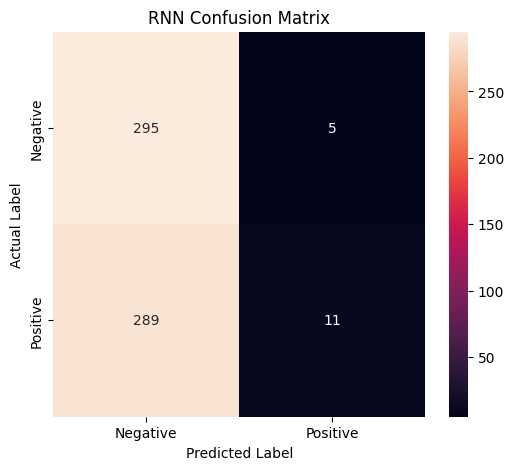

In [23]:
# ============================================
# Step 14: Confusion Matrix
# ============================================

cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("RNN Confusion Matrix")
plt.show()

## Step 15 — Test the RNN on New Reviews

To see how the trained RNN behaves on unseen text, we test it using three new movie-review sentences that were not part of the dataset.

The reviews include positive, negative, and mixed sentiment.

The same preprocessing used during training is applied to these reviews:

1. Tokenize using `cl100k_base`.
2. Truncate sequences longer than 756 tokens.
3. Pad shorter sequences to 756 tokens.
4. Pass the resulting tensor through the trained RNN.
5. Apply sigmoid to obtain the positive-class probability.
6. Classify the review as Positive if the probability is at least 0.5; otherwise classify it as Negative.

In [24]:
# ============================================
# Step 15: Test RNN on New Reviews
# ============================================

new_reviews = [
    "This movie was absolutely fantastic. The acting was brilliant and I loved every minute of it.",
    "The movie was boring and disappointing. The story was weak and I almost fell asleep.",
    "The movie had some good moments, but the story was confusing and the acting was only average."
]

def predict_sentiment(review):

    # Tokenize
    tokens = encoding.encode(review)

    # Truncate
    tokens = tokens[:MAX_LEN]

    # Pad
    if len(tokens) < MAX_LEN:
        tokens = tokens + [PAD_TOKEN_ID] * (MAX_LEN - len(tokens))

    # Convert to tensor
    input_tensor = torch.tensor(
        [tokens],
        dtype=torch.long
    ).to(device)

    # Prediction
    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        probability = torch.sigmoid(output).item()

    # Convert probability to sentiment
    if probability >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    return sentiment, probability


for review in new_reviews:

    sentiment, probability = predict_sentiment(review)

    print("\nReview:")
    print(review)

    print(f"Predicted sentiment: {sentiment}")
    print(f"Positive probability: {probability:.4f}")


Review:
This movie was absolutely fantastic. The acting was brilliant and I loved every minute of it.
Predicted sentiment: Negative
Positive probability: 0.4837

Review:
The movie was boring and disappointing. The story was weak and I almost fell asleep.
Predicted sentiment: Negative
Positive probability: 0.4837

Review:
The movie had some good moments, but the story was confusing and the acting was only average.
Predicted sentiment: Negative
Positive probability: 0.4837


# Activity 1 — RNN Results Summary

A simple RNN-based sentiment classifier was trained using a subset of 3,000 reviews from the provided IMDB dataset.

The reviews were tokenized using the `cl100k_base` tokenizer from `tiktoken`. The 95th percentile of the token-length distribution was approximately 756 tokens, so a maximum sequence length of 756 was selected. Reviews shorter than this length were padded, while longer reviews were truncated.

The dataset was divided into 80% training data (2,400 reviews) and 20% testing data (600 reviews), using stratification to maintain the class distribution.

### RNN Performance

- **Test Accuracy:** 51.00%
- **Positive Precision:** 68.75%
- **Positive Recall:** 3.67%
- **Positive F1-score:** 6.96%

The confusion matrix was:

[[295, 5],
 [289, 11]]

The model correctly classified 295 negative reviews and only 11 positive reviews. Therefore, the RNN showed a strong tendency to predict reviews as negative.

When tested on three new review sentences, the RNN predicted all three as negative and produced almost identical positive probabilities. This indicates that the simple RNN did not learn a strong distinction between positive and negative sentiment in this experiment.

Possible reasons include the relatively small training sample of 2,400 reviews, the long sequence length of up to 756 tokens, and the difficulty of a vanilla RNN in retaining useful information over long sequences.

This result will serve as the baseline for Activity 2, where the RNN will be replaced with an LSTM while keeping the dataset, preprocessing, train/test split, and evaluation approach the same.

In [26]:
!git clone https://github.com/MayuriMengji/GENAI_LLM_Engineering_SCFP125016.git

Cloning into 'GENAI_LLM_Engineering_SCFP125016'...
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 7 (delta 0), reused 4 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (7/7), 11.12 KiB | 5.56 MiB/s, done.


In [27]:
%cd GENAI_LLM_Engineering_SCFP125016

/content/GENAI_LLM_Engineering_SCFP125016


In [28]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [29]:
!find . -maxdepth 2 -type f

./.git/description
./.git/HEAD
./.git/index
./.git/packed-refs
./.git/config
./Activity_1/TextClassificationWithRNN.ipynb
./README.md


In [30]:
!rm "Activity_1/TextClassificationWithRNN.ipynb"

In [31]:
!find . -maxdepth 2 -type f

./.git/description
./.git/HEAD
./.git/index
./.git/packed-refs
./.git/config
./README.md


In [32]:
!find /content -maxdepth 2 -name "*.ipynb"